<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HecktorLR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 24.8MB/s]



DATA SUMMARY
Rows: 588
Class distribution: {0: 58, 1: 530}
Number of predictors: 8
Predictors: ['Age', 'Gender', 'Tobacco Consumption', 'Alcohol Consumption', 'Performance Status', 'T-stage', 'N-stage', 'M-stage']

DATA SPLIT
Total: 588 | Train: 381 | Validation: 89 | Test: 118
Train class counts: {0: 37, 1: 344}
Validation class counts: {0: 9, 1: 80}
Test class counts: {0: 12, 1: 106}

Automatic inverse-frequency class weights: {0: 5.148648648648648, 1: 0.5537790697674418}
SMOTE: False

VALIDATION RESULTS
Validation balanced accuracy: 0.7319
Selected threshold: 0.745

FINAL TEST METRICS
Accuracy             0.567797
Balanced_Accuracy    0.611635
Precision            0.936508
Recall               0.556604
F1                   0.698225
ROC_AUC              0.718553
PR_AUC               0.957388
Threshold            0.745000
dtype: float64

CONFUSION MATRIX
[[ 8  4]
 [47 59]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.15      0.67 

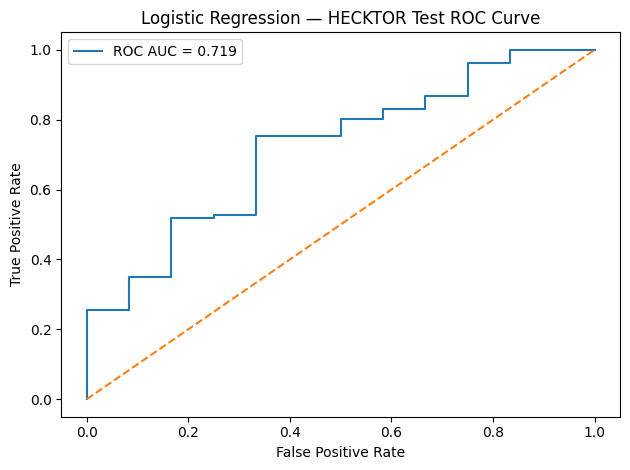

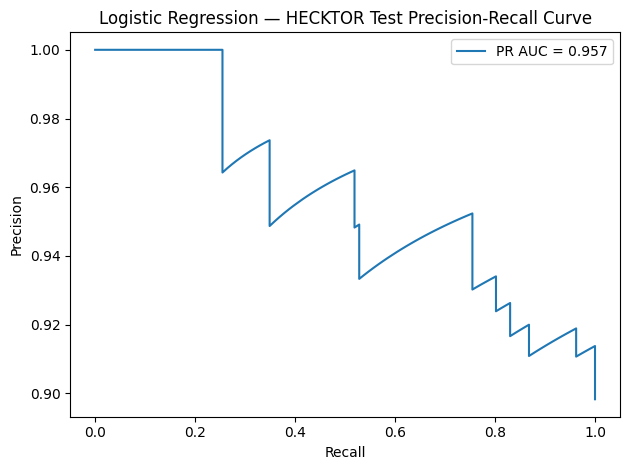


All outputs saved to: /content/drive/MyDrive/LR_results_HECKTOR
Files:
 - /content/drive/MyDrive/LR_results_HECKTOR/metrics.csv
 - /content/drive/MyDrive/LR_results_HECKTOR/test_predictions.csv
 - /content/drive/MyDrive/LR_results_HECKTOR/settings.json
 - /content/drive/MyDrive/LR_results_HECKTOR/roc_curve.png
 - /content/drive/MyDrive/LR_results_HECKTOR/pr_curve.png


In [1]:

!pip install -q gdown

import os
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gdown

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# LOGISTIC REGRESSION — HECKTOR HPV CLASSIFIER
# Hancock-aligned methodology | Seed 42 | No SMOTE
# ============================================================

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

drive.mount("/content/drive")

# ============================================================
# 1. LOAD AND PREPARE DATA
# ============================================================

gdown.download(
    id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",
    output="HPV2025.xlsx",
    quiet=False
)

BASE = "/content/drive/MyDrive"
OUT_DIR = os.path.join(BASE, "LR_results_HECKTOR")
os.makedirs(OUT_DIR, exist_ok=True)

df = pd.read_excel("HPV2025.xlsx")

# Remove rows without a target
df = df.dropna(subset=["HPV Status"]).copy()

# Keep patient ID for output only, not as a predictor
if "PatientID" in df.columns:
    df = df.rename(columns={"PatientID": "patient_id"})
elif "patient_id" not in df.columns:
    df["patient_id"] = np.arange(len(df))

# Convert target to binary 0/1
df["HPV_Label"] = pd.to_numeric(df["HPV Status"], errors="coerce")
df = df.dropna(subset=["HPV_Label"]).copy()
df = df[df["HPV_Label"].isin([0, 1])].copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

# Exactly eight predictors.
# Relapse, RFS and Treatment are excluded.
features = [
    "Age",
    "Gender",
    "Tobacco Consumption",
    "Alcohol Consumption",
    "Performance Status",
    "T-stage",
    "N-stage",
    "M-stage"
]

missing_features = [c for c in features if c not in df.columns]
if missing_features:
    raise KeyError(
        f"Missing predictor columns: {missing_features}\n"
        f"Available columns: {df.columns.tolist()}"
    )

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df = df[["patient_id"] + features + ["HPV_Label"]].copy()

print("\nDATA SUMMARY")
print("Rows:", len(df))
print("Class distribution:",
      df["HPV_Label"].value_counts().sort_index().to_dict())
print("Number of predictors:", len(features))
print("Predictors:", features)

# Ensure both classes have enough samples for stratified splitting
if df["HPV_Label"].nunique() != 2:
    raise ValueError("HPV_Label must contain both classes 0 and 1.")

if df["HPV_Label"].value_counts().min() < 5:
    raise ValueError(
        "Too few samples in one class for the stratified "
        "train/validation/test split."
    )

# ============================================================
# 2. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# Same two-stage split as Hancock: 65% / 15% / 20%
# ============================================================

train_val, test = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["HPV_Label"]
)

train, val = train_test_split(
    train_val,
    test_size=0.1875,
    random_state=SEED,
    stratify=train_val["HPV_Label"]
)

train = train.copy()
val = val.copy()
test = test.copy()

print("\nDATA SPLIT")
print(
    "Total:", len(df),
    "| Train:", len(train),
    "| Validation:", len(val),
    "| Test:", len(test)
)

print("Train class counts:",
      train["HPV_Label"].value_counts().sort_index().to_dict())
print("Validation class counts:",
      val["HPV_Label"].value_counts().sort_index().to_dict())
print("Test class counts:",
      test["HPV_Label"].value_counts().sort_index().to_dict())

# ============================================================
# 3. IMPUTATION, ONE-HOT ENCODING AND SCALING
# Fit preprocessing on training data only
# ============================================================

numeric_features = ["Age"]
categorical_features = [
    c for c in features if c not in numeric_features
]

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    # Compatibility with older scikit-learn versions
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_features
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", encoder)
        ]),
        categorical_features
    )
])

X_train = preprocessor.fit_transform(train[features])
X_val = preprocessor.transform(val[features])
X_test = preprocessor.transform(test[features])

y_train = train["HPV_Label"].to_numpy()
y_val = val["HPV_Label"].to_numpy()
y_test = test["HPV_Label"].to_numpy()

# Calculate inverse-frequency class weights for reporting,
# as in the Hancock notebook.
counts = np.bincount(y_train, minlength=2)

if np.any(counts == 0):
    raise ValueError("Training split must contain both classes.")

class_weights = {
    i: float(len(y_train) / (2 * counts[i]))
    for i in range(2)
}

print("\nAutomatic inverse-frequency class weights:", class_weights)
print("SMOTE: False")

# ============================================================
# 4. TRAIN LOGISTIC REGRESSION
# Select threshold using validation data only
# ============================================================

model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=SEED
)

model.fit(X_train, y_train)

val_prob = model.predict_proba(X_val)[:, 1]

thresholds = np.linspace(0.10, 0.90, 161)

threshold_scores = [
    balanced_accuracy_score(
        y_val,
        (val_prob >= threshold).astype(int)
    )
    for threshold in thresholds
]

best_score = max(threshold_scores)

# If several thresholds tie, choose the one nearest 0.5
best_threshold = min(
    (
        threshold
        for threshold, score in zip(thresholds, threshold_scores)
        if np.isclose(score, best_score)
    ),
    key=lambda threshold: abs(threshold - 0.5)
)

print("\nVALIDATION RESULTS")
print(f"Validation balanced accuracy: {best_score:.4f}")
print(f"Selected threshold: {best_threshold:.3f}")

# ============================================================
# 5. FINAL TEST EVALUATION
# The test set is not used to select the threshold
# ============================================================

test_prob = model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

metrics = {
    "Accuracy": accuracy_score(y_test, test_pred),
    "Balanced_Accuracy": balanced_accuracy_score(y_test, test_pred),
    "Precision": precision_score(
        y_test, test_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_pred, zero_division=0
    ),
    "F1": f1_score(
        y_test, test_pred, zero_division=0
    ),
    "ROC_AUC": (
        roc_auc_score(y_test, test_prob)
        if len(np.unique(y_test)) == 2 else np.nan
    ),
    "PR_AUC": (
        average_precision_score(y_test, test_prob)
        if len(np.unique(y_test)) == 2 else np.nan
    ),
    "Threshold": float(best_threshold)
}

print("\nFINAL TEST METRICS")
print(pd.Series(metrics))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, test_pred))

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        test_pred,
        zero_division=0
    )
)

# Save metrics
pd.DataFrame([metrics]).to_csv(
    os.path.join(OUT_DIR, "metrics.csv"),
    index=False
)

# Save test predictions
pd.DataFrame({
    "patient_id": test["patient_id"].to_numpy(),
    "y_true": y_test,
    "probability_positive": test_prob,
    "prediction": test_pred
}).to_csv(
    os.path.join(OUT_DIR, "test_predictions.csv"),
    index=False
)

# Save settings and reproducibility information
settings = {
    "model": "Logistic Regression",
    "dataset": "HECKTOR",
    "seed": SEED,
    "features": features,
    "excluded_features": ["Relapse", "RFS", "Treatment"],
    "target_column": "HPV Status",
    "split_ratio": {
        "train": 0.65,
        "validation": 0.15,
        "test": 0.20
    },
    "split_counts": {
        "train": int(len(train)),
        "validation": int(len(val)),
        "test": int(len(test))
    },
    "threshold_selection": "Validation balanced accuracy",
    "threshold": float(best_threshold),
    "class_weight": "balanced",
    "class_weights_calculated_from_training_data": class_weights,
    "smote": False,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features
}

with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump(settings, f, indent=2)

# ============================================================
# 6. ROC AND PRECISION-RECALL CURVES
# ============================================================

if len(np.unique(y_test)) == 2:

    # ROC curve
    fpr, tpr, _ = roc_curve(y_test, test_prob)

    plt.figure()
    plt.plot(
        fpr,
        tpr,
        label=f"ROC AUC = {metrics['ROC_AUC']:.3f}"
    )
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Logistic Regression — HECKTOR Test ROC Curve")
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUT_DIR, "roc_curve.png"),
        dpi=150
    )
    plt.show()

    # Precision-recall curve
    precision, recall, _ = precision_recall_curve(
        y_test, test_prob
    )

    plt.figure()
    plt.plot(
        recall,
        precision,
        label=f"PR AUC = {metrics['PR_AUC']:.3f}"
    )
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(
        "Logistic Regression — HECKTOR Test Precision-Recall Curve"
    )
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUT_DIR, "pr_curve.png"),
        dpi=150
    )
    plt.show()

# ============================================================
# 7. FINISH
# ============================================================

print("\nAll outputs saved to:", OUT_DIR)
print("Files:")
for filename in [
    "metrics.csv",
    "test_predictions.csv",
    "settings.json",
    "roc_curve.png",
    "pr_curve.png"
]:
    print(" -", os.path.join(OUT_DIR, filename))
